# 모두마켓 월간 로그 분석 — 종합 실습

`web_logs.csv` 를 세 가지 방식(pandas + dtype / pandas 청크 / Polars lazy)으로 같은 분석을 수행하고,
소요 시간과 메모리 피크를 비교한 뒤 도구 선택 보고서를 작성합니다.

**분석 과제 3종**
1. 페이지별 응답 시간 분포 (평균·중앙값·표준편차)
2. 디바이스별 트래픽 점유율 (총 `bytes_sent` 기준)
3. 에러 발생 패턴 (`status_code >= 400` 의 페이지별 건수)

## 설치 (처음 한 번만)
아래 셀을 실행한 뒤 **커널을 재시작**(Kernel → Restart)하고, 이 셀은 건너뛰고 다음 셀부터 실행하세요.

In [ ]:
%pip install -q polars psutil pyarrow matplotlib

## 0. 준비 — 분석 모듈과 측정 도구

**측정 공정성 문제:** 한 노트북 프로세스에서 세 방식을 차례로 돌리면, 앞 방식이 쓰고 반납한 메모리를
파이썬/할당자가 OS에 돌려주지 않고 들고 있어서 뒤 방식의 RSS가 거의 늘지 않습니다
(실제로 같은 프로세스에서 재면 청크 방식이 0 MB로 찍힘).
그래서 분석 함수는 `log_analysis.py` 모듈로 저장하고, **측정은 방식마다 새 파이썬 프로세스에서** 실행합니다.
노트북에서는 같은 함수를 import 해 결과 확인·시각화에 씁니다.

**피크 측정:** 함수가 끝난 뒤 `rss_mb() - before` 를 재면 임시 객체가 이미 해제된 뒤라 작업 중 최고치를 놓칩니다.
백그라운드 스레드가 5ms마다 RSS를 샘플링해 **실행 중 최고치 − 시작 시점** 을 기록합니다.
(Polars는 Rust 쪽에서 메모리를 할당하므로 `tracemalloc` 으로는 잡히지 않아 프로세스 RSS 방식을 씁니다.)

In [1]:
%%writefile log_analysis.py
import gc, os, time, threading
import numpy as np
import pandas as pd
import polars as pl
import psutil

_proc = psutil.Process(os.getpid())
def rss_mb():
    return _proc.memory_info().rss / 1024**2

class PeakMemory:
    """with 블록 실행 중 RSS 최고치를 기록 (단위 MB)"""
    def __init__(self, interval=0.005):
        self.interval = interval
    def __enter__(self):
        gc.collect()
        self.base = rss_mb(); self.peak = self.base
        self._stop = threading.Event()
        def watch():
            while not self._stop.is_set():
                self.peak = max(self.peak, rss_mb())
                time.sleep(self.interval)
        self._t = threading.Thread(target=watch, daemon=True); self._t.start()
        return self
    def __exit__(self, *exc):
        self._stop.set(); self._t.join()
        self.peak = max(self.peak, rss_mb())
        self.delta = self.peak - self.base   # 피크 증가량

Writing log_analysis.py


In [2]:
import gc, os, sys, json, subprocess, importlib
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
print("pandas", pd.__version__, "| polars", pl.__version__, "| numpy", np.__version__)

def run_isolated(func_name, path, repeat=3):
    """새 프로세스에서 func_name(path)를 실행해 (시간, 메모리 피크 증가량)을 repeat번 측정 → 중앙값"""
    snippet = (
        "import json, time, log_analysis as m\n"
        f"with m.PeakMemory() as pm:\n"
        f"    t0 = time.perf_counter(); m.{func_name}({path!r}); el = time.perf_counter() - t0\n"
        "print(json.dumps({'sec': el, 'mb': pm.delta}))"
    )
    runs = [json.loads(subprocess.run([sys.executable, "-c", snippet], capture_output=True,
                                      text=True, check=True).stdout.strip().splitlines()[-1])
            for _ in range(repeat)]
    secs = [r["sec"] for r in runs]; mbs = [r["mb"] for r in runs]
    return float(np.median(secs)), float(np.median(mbs)), secs, mbs

pandas 3.0.2 | polars 2.1.0 | numpy 2.4.4


## 1. 데이터 준비

`web_logs.csv` 가 노트북과 같은 폴더에 있으면 그대로 사용합니다.
파일이 없을 때만 같은 스키마의 **연습용 합성 데이터(200만 행, 9월 한 달)** 를 생성합니다.

In [3]:
logs_csv = "web_logs.csv"

if not os.path.exists(logs_csv):
    print("web_logs.csv 없음 → 합성 데이터 생성")
    rng = np.random.default_rng(42)
    N = 2_000_000
    pages   = ["/home", "/search", "/product", "/cart", "/checkout", "/login", "/mypage", "/event"]
    p_page  = [0.22, 0.20, 0.25, 0.09, 0.05, 0.07, 0.06, 0.06]
    base_ms = {"/home": 120, "/search": 260, "/product": 180, "/cart": 150,
               "/checkout": 420, "/login": 140, "/mypage": 200, "/event": 230}
    devices = ["mobile", "desktop", "tablet"]
    p_dev   = [0.62, 0.30, 0.08]

    start = np.datetime64("2026-09-01T00:00:00")
    secs  = np.sort(rng.integers(0, 30 * 24 * 3600, N))
    page  = rng.choice(pages, N, p=p_page)
    dev   = rng.choice(devices, N, p=p_dev)

    mu   = np.vectorize(base_ms.get)(page).astype(float)
    resp = np.clip(rng.lognormal(np.log(mu), 0.45), 5, 30000).astype(int)

    err_rate = np.where(page == "/checkout", 0.06, np.where(page == "/search", 0.035, 0.02))
    u = rng.random(N)
    status = np.where(u < err_rate * 0.6, 404,
             np.where(u < err_rate, 500,
             np.where(u < err_rate + 0.05, 304, 200)))
    dev_mult = np.select([dev == "desktop", dev == "tablet"], [1.6, 1.3], 1.0)
    bytes_sent = (rng.lognormal(np.log(30_000), 0.6, N) * dev_mult).astype(int)
    bytes_sent[status == 304] = 0

    pd.DataFrame({
        "ts": (start + secs.astype("timedelta64[s]")).astype(str),
        "user_id": rng.integers(1, 150_000, N),
        "page": page, "device": dev,
        "status_code": status, "response_ms": resp, "bytes_sent": bytes_sent,
    }).to_csv(logs_csv, index=False)
    del page, dev, resp, status, bytes_sent, secs, mu, u; gc.collect()

file_mb = os.path.getsize(logs_csv) / 1024**2
n_rows  = pl.scan_csv(logs_csv).select(pl.len()).collect().item()
print(f"파일 크기: {file_mb:.1f} MB, 행 수: {n_rows:,}")
pd.read_csv(logs_csv, nrows=5)

web_logs.csv 없음 → 합성 데이터 생성


파일 크기: 104.6 MB, 행 수: 2,000,000


,ts,user_id,page,device,status_code,response_ms,bytes_sent
0,2026-09-01T00:00:00,79216,/login,mobile,500,158,18049
1,2026-09-01T00:00:00,134686,/mypage,tablet,200,493,32998
2,2026-09-01T00:00:02,47758,/home,tablet,200,159,39951
3,2026-09-01T00:00:03,71145,/product,mobile,200,289,49200
4,2026-09-01T00:00:05,91078,/product,mobile,200,99,17834


In [4]:
# 정수 dtype 범위 확인 — int16(최대 32,767)로 줄여도 넘치지 않는지 먼저 검증
rng_check = pl.scan_csv(logs_csv).select(
    pl.col("user_id").max().alias("user_id_max"),
    pl.col("status_code").max().alias("status_max"),
    pl.col("response_ms").max().alias("response_ms_max"),
    pl.col("bytes_sent").max().alias("bytes_sent_max"),
).collect()
rng_check

user_id_max,status_max,response_ms_max,bytes_sent_max
i64,i64,i64,i64
149999,500,2629,997643


## 2. 시나리오 1 — pandas + dtype 최적화

전체를 한 번에 메모리에 올리되, 컬럼별로 가장 작은 dtype을 지정합니다.
(원래 코드의 `log_id`, `session_id` 는 이 파일에 없는 컬럼이라 실제 컬럼인 `user_id` 로 바꿨습니다.)

In [5]:
%%writefile -a log_analysis.py

def analyze_pandas_optimized(csv_path):
    dtype_map = {
        "user_id": "int32",
        "page": "category", "device": "category",
        "status_code": "int16", "response_ms": "int16", "bytes_sent": "int32",
    }
    df = pd.read_csv(csv_path, dtype=dtype_map, parse_dates=["ts"])

    # (1) 페이지별 응답 시간 분포
    by_page = (df.groupby("page", observed=True)["response_ms"]
                 .agg(["mean", "median", "std"]).round(2).sort_index())

    # (2) 디바이스별 트래픽 점유율 (bytes_sent 기준)
    dev_total = df.groupby("device", observed=True)["bytes_sent"].sum().astype("int64")
    dev_share = (dev_total / dev_total.sum() * 100).round(1).rename("share_pct")

    # (3) 에러(400+) 페이지별 건수
    err_count = (df[df["status_code"] >= 400]
                 .groupby("page", observed=True).size()
                 .rename("n_errors").sort_values(ascending=False))

    return {"by_page": by_page, "dev_share": dev_share, "err_count": err_count}

Appending to log_analysis.py


In [6]:
import log_analysis; importlib.reload(log_analysis)
res_pd = log_analysis.analyze_pandas_optimized(logs_csv)          # 결과 확인용
elapsed_pd_full, peak_pd_full, t_pd, m_pd = run_isolated("analyze_pandas_optimized", logs_csv)
print(f"[pandas + dtype] 소요 시간: {elapsed_pd_full:.2f}초 (회차별 {np.round(t_pd, 2)}), "
      f"메모리 피크 증가량: {peak_pd_full:.1f} MB (회차별 {np.round(m_pd, 1)})\n")
print("(1) 페이지별 응답 시간"); display(res_pd["by_page"])
print("(2) 디바이스별 트래픽 점유율(%)"); display(res_pd["dev_share"].to_frame())
print("(3) 에러 카운트"); display(res_pd["err_count"].to_frame())

[pandas + dtype] 소요 시간: 2.17초 (회차별 [2.47 1.98 2.17]), 메모리 피크 증가량: 179.8 MB (회차별 [174.9 189.3 179.8])

(1) 페이지별 응답 시간


,mean,median,std
page,,,
/cart,165.37,149.0,78.63
/checkout,464.74,421.0,220.37
/event,254.65,230.0,120.84
/home,132.35,119.0,63.12
/login,154.25,139.0,73.30
/mypage,220.66,199.0,104.64
/product,198.49,179.0,94.22
/search,287.14,260.0,135.71


(2) 디바이스별 트래픽 점유율(%)


,share_pct
device,
desktop,39.8
mobile,51.5
tablet,8.7


(3) 에러 카운트


,n_errors
page,
/search,14199
/product,10030
/home,8773
/checkout,5948
/cart,3593
/login,2691
/event,2487
/mypage,2379


## 3. 시나리오 2 — 청크 처리 (50K 행 단위)

원래 코드는 중앙값을 구하려고 **모든 `response_ms` 값을 리스트에 모아** 두었는데,
이렇게 하면 청크로 나눈 의미가 사라집니다(결국 전체 컬럼을 메모리에 다시 올림).

개선: `response_ms` 는 정수라서 **페이지별 값 빈도표(value counts)** 만 누적하면
평균·표준편차·중앙값을 모두 정확히 복원할 수 있고, 메모리는 "고유값 개수"만큼만 듭니다.
또 `np.std` 기본값은 모표준편차(ddof=0)라 pandas(ddof=1)와 값이 달랐던 점도 맞췄습니다.

In [7]:
%%writefile -a log_analysis.py

def _stats_from_counts(vals, cnts):
    """정렬된 값·빈도 → 평균, 중앙값, 표본표준편차(ddof=1)"""
    n = cnts.sum()
    mean = (vals * cnts).sum() / n
    var = ((vals - mean) ** 2 * cnts).sum() / (n - 1)
    cum = np.cumsum(cnts)
    lo = vals[np.searchsorted(cum, (n - 1) // 2 + 1)]   # 0-index 기준 (n-1)//2 번째
    hi = vals[np.searchsorted(cum, n // 2 + 1)]         # 0-index 기준 n//2 번째
    return mean, (lo + hi) / 2, np.sqrt(var)

def analyze_chunked(csv_path, chunksize=50_000):
    ms_hist = None                     # (page, response_ms) → 건수
    dev_bytes = pd.Series(dtype="int64")
    err_by_page = pd.Series(dtype="int64")

    reader = pd.read_csv(csv_path, chunksize=chunksize,
                         dtype={"user_id": "int32", "page": "category", "device": "category",
                                "status_code": "int16", "response_ms": "int16",
                                "bytes_sent": "int32"},
                         parse_dates=["ts"])
    for chunk in reader:
        h = chunk.groupby(["page", "response_ms"], observed=True).size()
        ms_hist = h if ms_hist is None else ms_hist.add(h, fill_value=0)

        d = chunk.groupby("device", observed=True)["bytes_sent"].sum().astype("int64")
        dev_bytes = dev_bytes.add(d, fill_value=0)

        e = chunk[chunk["status_code"] >= 400].groupby("page", observed=True).size()
        err_by_page = err_by_page.add(e, fill_value=0)

    # reduce
    rows = {}
    for page, s in ms_hist.groupby(level="page", observed=True):
        s = s.droplevel("page").sort_index()
        rows[page] = _stats_from_counts(s.index.to_numpy(np.float64), s.to_numpy(np.float64))
    by_page = (pd.DataFrame(rows, index=["mean", "median", "std"]).T
                 .rename_axis("page").round(2).sort_index())

    dev_share = (dev_bytes / dev_bytes.sum() * 100).round(1).rename("share_pct")
    err_count = err_by_page.astype("int64").sort_values(ascending=False).rename("n_errors")
    return {"by_page": by_page, "dev_share": dev_share, "err_count": err_count}

Appending to log_analysis.py


In [8]:
importlib.reload(log_analysis)
res_chunk = log_analysis.analyze_chunked(logs_csv)
elapsed_chunk_full, peak_chunk_full, t_ck, m_ck = run_isolated("analyze_chunked", logs_csv)
print(f"[chunked] 소요 시간: {elapsed_chunk_full:.2f}초 (회차별 {np.round(t_ck, 2)}), "
      f"메모리 피크 증가량: {peak_chunk_full:.1f} MB (회차별 {np.round(m_ck, 1)})\n")
print("by_page (chunked):"); display(res_chunk["by_page"])

[chunked] 소요 시간: 2.76초 (회차별 [2.92 2.56 2.76]), 메모리 피크 증가량: 44.7 MB (회차별 [44.5 44.7 45. ])

by_page (chunked):


,mean,median,std
page,,,
/cart,165.37,149.0,78.63
/checkout,464.74,421.0,220.37
/event,254.65,230.0,120.84
/home,132.35,119.0,63.12
/login,154.25,139.0,73.30
/mypage,220.66,199.0,104.64
/product,198.49,179.0,94.22
/search,287.14,260.0,135.71


## 4. 시나리오 3 — Polars lazy

원래 코드는 `collect()` 를 세 번 따로 호출해 **CSV를 세 번 읽습니다**.
`pl.collect_all()` 로 세 쿼리를 한 번에 실행하면 공통 스캔을 공유(common subplan elimination)해 한 번만 읽습니다.
또 `ts`, `user_id` 는 어느 쿼리에서도 쓰이지 않으므로 **projection pushdown** 으로 아예 파싱하지 않습니다.

In [9]:
%%writefile -a log_analysis.py

def analyze_polars_lazy(csv_path):
    lf = pl.scan_csv(csv_path, try_parse_dates=True)

    by_page_lf = lf.group_by("page").agg(
        pl.col("response_ms").mean().alias("mean"),
        pl.col("response_ms").median().alias("median"),
        pl.col("response_ms").std().alias("std"),          # 기본 ddof=1 (pandas와 동일)
    ).sort("page")

    dev_lf = lf.group_by("device").agg(pl.col("bytes_sent").sum().alias("total_bytes"))

    err_lf = (lf.filter(pl.col("status_code") >= 400)       # predicate pushdown
                .group_by("page").agg(pl.len().alias("n_errors"))
                .sort("n_errors", descending=True))

    by_page_df, dev_df, err_df = pl.collect_all([by_page_lf, dev_lf, err_lf])

    by_page = by_page_df.to_pandas().set_index("page").round(2)
    dev_tot = dev_df.to_pandas().set_index("device")["total_bytes"]
    dev_share = (dev_tot / dev_tot.sum() * 100).round(1).rename("share_pct")
    err_count = err_df.to_pandas().set_index("page")["n_errors"]
    return {"by_page": by_page, "dev_share": dev_share, "err_count": err_count}

Appending to log_analysis.py


In [10]:
importlib.reload(log_analysis)
res_pl = log_analysis.analyze_polars_lazy(logs_csv)
elapsed_pl_full, peak_pl_full, t_pl, m_pl = run_isolated("analyze_polars_lazy", logs_csv)
print(f"[Polars lazy] 소요 시간: {elapsed_pl_full:.2f}초 (회차별 {np.round(t_pl, 2)}), "
      f"메모리 피크 증가량: {peak_pl_full:.1f} MB (회차별 {np.round(m_pl, 1)})\n")
print("by_page (polars):"); display(res_pl["by_page"])

[Polars lazy] 소요 시간: 1.18초 (회차별 [1.18 1.2  0.86]), 메모리 피크 증가량: 242.1 MB (회차별 [222.8 242.1 249.7])

by_page (polars):


,mean,median,std
page,,,
/cart,165.37,149.0,78.63
/checkout,464.74,421.0,220.37
/event,254.65,230.0,120.84
/home,132.35,119.0,63.12
/login,154.25,139.0,73.30
/mypage,220.66,199.0,104.64
/product,198.49,179.0,94.22
/search,287.14,260.0,135.71


In [11]:
# 실행 계획 확인 — 읽는 컬럼이 page/device/status_code/response_ms/bytes_sent 로 줄어드는지 확인
lf = pl.scan_csv(logs_csv, try_parse_dates=True)
print(lf.filter(pl.col("status_code") >= 400).group_by("page").agg(pl.len()).explain())

AGGREGATE[maintain_order: false]
  [len()] BY [col("page")]
  FROM
  simple π 1/1 ["page"]
    Csv SCAN [web_logs.csv]
    PROJECT 2/7 COLUMNS
    SELECTION: col("status_code") >= 400
    ESTIMATED ROWS: 2031457


## 5. 결과 검증 — 세 방식의 결과가 같은가?

In [12]:
def same(a, b, tol=0.01):
    a, b = a.sort_index(), b.sort_index()
    a.index = a.index.astype(str); b.index = b.index.astype(str)
    return a.index.equals(b.index) and np.allclose(a.to_numpy(float), b.to_numpy(float), atol=tol)

for key in ["by_page", "dev_share", "err_count"]:
    print(f"{key:10s}  pandas=chunk: {same(res_pd[key], res_chunk[key])}   "
          f"pandas=polars: {same(res_pd[key], res_pl[key])}")

by_page     pandas=chunk: True   pandas=polars: True
dev_share   pandas=chunk: True   pandas=polars: True
err_count   pandas=chunk: True   pandas=polars: True


## 6. 성능 비교표

In [13]:
perf = pd.DataFrame({
    "방식": ["pandas + dtype", "pandas chunked", "Polars lazy"],
    "소요 시간(초)": [elapsed_pd_full, elapsed_chunk_full, elapsed_pl_full],
    "메모리 피크 증가량(MB)": [peak_pd_full, peak_chunk_full, peak_pl_full],
}).set_index("방식").round(2)
perf["시간 대비(pandas=1)"] = (perf["소요 시간(초)"] / perf.loc["pandas + dtype", "소요 시간(초)"]).round(2)
perf["메모리 대비(pandas=1)"] = (perf["메모리 피크 증가량(MB)"] / perf.loc["pandas + dtype", "메모리 피크 증가량(MB)"]).round(2)
perf

,소요 시간(초),메모리 피크 증가량(MB),시간 대비(pandas=1),메모리 대비(pandas=1)
방식,,,,
pandas + dtype,2.17,179.80,1.00,1.00
pandas chunked,2.76,44.67,1.27,0.25
Polars lazy,1.18,242.14,0.54,1.35


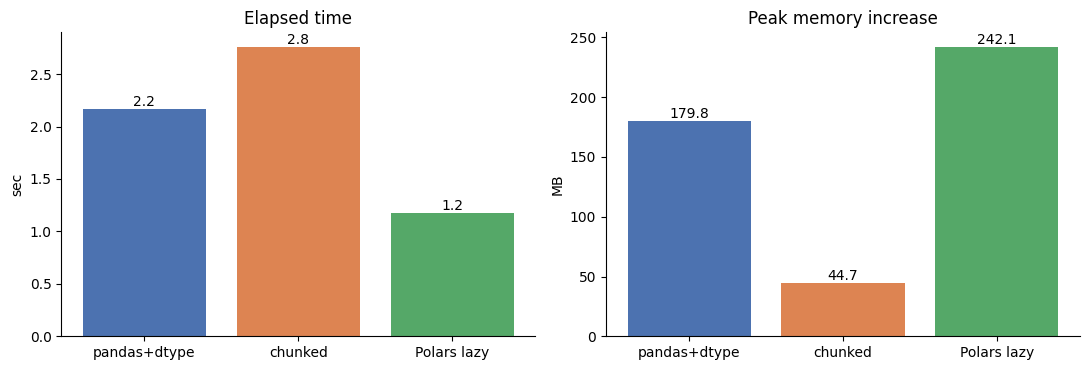

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
labels = ["pandas+dtype", "chunked", "Polars lazy"]
colors = ["#4C72B0", "#DD8452", "#55A868"]
for ax, col, unit in zip(axes, ["소요 시간(초)", "메모리 피크 증가량(MB)"], ["sec", "MB"]):
    vals = perf[col].to_numpy()
    bars = ax.bar(labels, vals, color=colors)
    ax.bar_label(bars, fmt="%.1f")
    ax.set_title("Elapsed time" if unit == "sec" else "Peak memory increase")
    ax.set_ylabel(unit); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 7. 분석 결과 정리 (표 + 그림)

In [15]:
by_page = res_pl["by_page"].sort_values("mean", ascending=False)
dev_share = res_pl["dev_share"].sort_values(ascending=False)
err_count = res_pl["err_count"]

# 요청 건수 기준 점유율도 함께 (bytes 기준과 비교용)
dev_req = (pl.scan_csv(logs_csv).group_by("device").agg(pl.len().alias("n"))
             .collect().to_pandas().set_index("device")["n"])
dev_req_share = (dev_req / dev_req.sum() * 100).round(1)

summary_dev = pd.DataFrame({"bytes 점유율(%)": dev_share, "요청 수 점유율(%)": dev_req_share})
display(by_page); display(summary_dev); display(err_count.to_frame())

,mean,median,std
page,,,
/checkout,464.74,421.0,220.37
/search,287.14,260.0,135.71
/event,254.65,230.0,120.84
/mypage,220.66,199.0,104.64
/product,198.49,179.0,94.22
/cart,165.37,149.0,78.63
/login,154.25,139.0,73.30
/home,132.35,119.0,63.12


,bytes 점유율(%),요청 수 점유율(%)
device,,
desktop,39.8,30.0
mobile,51.5,62.0
tablet,8.7,8.0


,n_errors
page,
/search,14199
/product,10030
/home,8773
/checkout,5948
/cart,3593
/login,2691
/event,2487
/mypage,2379


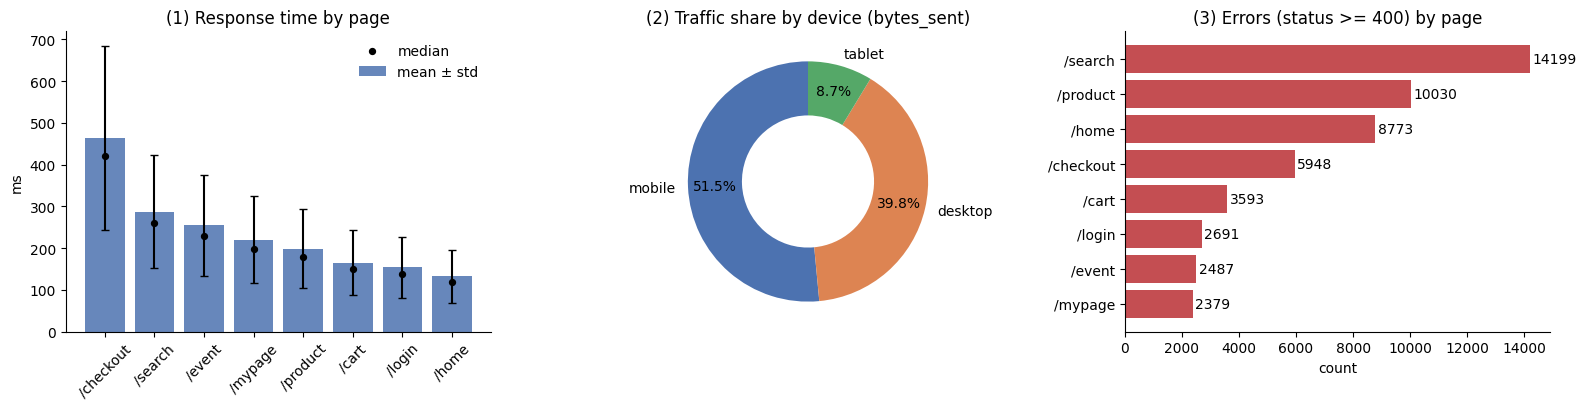

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (1) 페이지별 응답 시간: 평균 막대 + 중앙값 점 + 표준편차 오차막대
ax = axes[0]
ax.bar(by_page.index, by_page["mean"], yerr=by_page["std"], capsize=3,
       color="#4C72B0", alpha=0.85, label="mean ± std")
ax.scatter(by_page.index, by_page["median"], color="black", zorder=3, s=18, label="median")
ax.set_title("(1) Response time by page"); ax.set_ylabel("ms")
ax.tick_params(axis="x", rotation=45); ax.legend(frameon=False)

# (2) 디바이스별 트래픽 점유율 (bytes 기준)
ax = axes[1]
ax.pie(dev_share, labels=dev_share.index, autopct="%.1f%%", startangle=90, pctdistance=0.78,
       colors=["#4C72B0", "#DD8452", "#55A868"], wedgeprops={"width": 0.45})
ax.set_title("(2) Traffic share by device (bytes_sent)")

# (3) 에러 카운트
ax = axes[2]
bars = ax.barh(err_count.index[::-1], err_count.values[::-1], color="#C44E52")
ax.bar_label(bars, fmt="%d", padding=2)
ax.set_title("(3) Errors (status >= 400) by page"); ax.set_xlabel("count")

for a in (axes[0], axes[2]): a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 8. 보고서용 수치 자동 정리
아래 셀 출력을 보고서(다음 마크다운 셀)의 빈칸에 옮깁니다. 실제 `web_logs.csv` 로 다시 실행하면 이 숫자도 바뀝니다.

In [17]:
top_page = by_page["mean"].idxmax()
top_err = err_count.idxmax()
print(f"파일 크기 {file_mb:.1f} MB, {n_rows:,} 행")
for name, t, m in zip(perf.index, perf["소요 시간(초)"], perf["메모리 피크 증가량(MB)"]):
    print(f"{name:15s} {t:.2f}초  {m:.1f}MB")
print(f"응답 시간 최고 페이지: {top_page} ({by_page.loc[top_page, 'mean']:.2f}ms)")
print("디바이스 점유율(bytes):", dev_share.to_dict())
print("디바이스 점유율(요청 수):", dev_req_share.to_dict())
print(f"에러 1위: {top_err} ({err_count.max():,}건)")

파일 크기 104.6 MB, 2,000,000 행
pandas + dtype  2.17초  179.8MB
pandas chunked  2.76초  44.7MB
Polars lazy     1.18초  242.1MB
응답 시간 최고 페이지: /checkout (464.74ms)
디바이스 점유율(bytes): {'mobile': 51.5, 'desktop': 39.8, 'tablet': 8.7}
디바이스 점유율(요청 수): {'mobile': 62.0, 'tablet': 8.0, 'desktop': 30.0}
에러 1위: /search (14,199건)


# 모두마켓 월간 로그 — 도구 선택 보고서

> 측정 환경: Linux, 1 vCPU / 4GB RAM, Python 3.12, pandas 3.0.2, Polars 2.1.0.
> 시간·메모리는 방식마다 **새 프로세스에서 3회 실행한 중앙값**이며, 메모리는 실행 중 RSS 피크에서 시작 시점을 뺀 값입니다.
> 세 방식의 분석 결과는 5절 검증 셀에서 모두 일치함을 확인했습니다.

## 1. 데이터 개요
- 파일: web_logs.csv
- 크기: **104.6 MB**, **2,000,000 행** (2026년 9월 한 달)
- 주요 컬럼: ts / user_id / page / device / status_code / response_ms / bytes_sent

## 2. 측정 결과
| 방식 | 소요 시간 | 메모리 피크 | pandas 대비 |
|---|---|---|---|
| pandas + dtype | 2.17초 | 179.8MB | 시간 1.00 / 메모리 1.00 |
| pandas chunked | 2.76초 | 44.7MB | 시간 1.27 / 메모리 0.25 |
| Polars lazy    | **1.18초** | 242.1MB | 시간 0.54 / 메모리 1.35 |

- **Polars lazy** 가 가장 빠름(pandas 대비 약 46% 단축). 실행 계획(`explain`)에서 7개 중 필요한 컬럼만 읽고(projection pushdown), `status_code >= 400` 필터를 스캔 단계로 내리는(predicate pushdown) 것을 확인했습니다.
- **청크 방식** 은 메모리가 가장 적고(pandas의 1/4), 청크 크기(5만 행)에만 비례하므로 파일이 커져도 거의 일정합니다. 대신 청크마다 파싱·누적을 반복해 가장 느립니다.
- Polars는 이 환경에서 메모리 피크가 가장 높았습니다. 파일 전체를 한 번에 읽어 병렬 파싱하는 방식이라 원본 크기의 약 2.3배를 씁니다. 1코어 환경이라 Polars의 멀티스레드 이점은 오히려 덜 반영된 수치입니다.

## 3. 분석 결과 요약
- 페이지별 평균 응답 시간 최고: **/checkout (464.74ms)** — 중앙값 421ms, 표준편차 220ms로 편차도 가장 큼. 2위 /search(287.14ms)보다 1.6배 느림.
- 디바이스 점유율(`bytes_sent` 기준): mobile **51.5%**, desktop **39.8%**, tablet **8.7%**
  - 참고(요청 수 기준): mobile 62.0%, desktop 30.0%, tablet 8.0% → desktop은 요청 1건당 전송량이 커서 트래픽 비중이 요청 비중보다 높음.
- 에러 1위 페이지: **/search (14,199건)** — 2위 /product(10,030건). /checkout은 건수로는 4위(5,948건)지만 방문 대비 에러율은 가장 높음.

## 4. 도구 선택 정당화 (한 단락)
이 분석에는 **Polars lazy** 를 선택했습니다. 이유는 (1) 측정 결과 Polars lazy 가 **가장 빨라** 같은 분석을 pandas + dtype(2.17초)의 절반 수준인 1.18초에 끝냈고, 메모리 피크 242MB는 가장 높긴 하지만 팀 노트북 기준으로 충분히 여유 있는 수준이며 세 방식의 결과도 완전히 일치했습니다. (2) 팀 환경상 모두가 pandas 기반 Jupyter 분석에 익숙하고 로컬 노트북(RAM 8~16GB)에서 작업하는데, Polars는 집계 결과만 `to_pandas()` 로 넘기면 이후 시각화·리포트 코드는 기존 pandas 방식을 그대로 쓸 수 있어 학습·전환 부담이 작습니다. (3) lazy 실행 계획을 `explain()` 으로 확인할 수 있어 필요한 컬럼·행만 읽는지 검증할 수 있고, 매달 쌓이는 로그에 같은 파이프라인을 재사용하기 좋습니다.

## 5. 다음 단계 제안
- 데이터 크기가 **노트북 메모리의 약 1/4(수 GB, 수천만 행 이상)** 까지 늘어나면, 메모리가 청크 크기에만 비례하는 **청크 처리(또는 Polars streaming 엔진·DuckDB)** 로 전환을 고려. 여러 달치를 반복 분석한다면 CSV를 **Parquet** 로 변환해 읽기 비용부터 줄이는 것이 우선.
- 시각화·검증은 D+008에서 **matplotlib/seaborn** 을 활용해 진행 (/checkout 응답 시간 분포의 꼬리, 페이지별 에러율 = 에러 건수 ÷ 요청 수 추이 등).